EDA_2 after cleaning the data

In [7]:
import pandas as pd

df = pd.read_csv(
    "../../data/processed/BeijingHousingPrices_cleaned.csv",
    parse_dates=["tradeTime"],     # CSVs store dates as text, so parse them back
    dtype={"id": "string"},        # keep IDs as text
)
print(df.shape)

(297490, 25)


In [21]:
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from cleaning import clean_dataframe

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297490 entries, 0 to 297489
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   url                  297490 non-null  str           
 1   id                   297490 non-null  string        
 2   Lng                  297490 non-null  float64       
 3   Lat                  297490 non-null  float64       
 4   Cid                  297490 non-null  int64         
 5   tradeTime            297490 non-null  datetime64[us]
 6   followers            297490 non-null  int64         
 7   totalPrice           297490 non-null  float64       
 8   price                297490 non-null  float64       
 9   square               297490 non-null  float64       
 10  livingRoom           297490 non-null  int64         
 11  drawingRoom          297490 non-null  int64         
 12  kitchen              297490 non-null  int64         
 13  bathRoom             2974

In [26]:
code_cols = ["buildingType", "renovationCondition", "buildingStructure",
             "elevator", "fiveYearsProperty", "subway", "district"]

df.drop(columns=code_cols).describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Lng,297490.0,116.418602,116.072514,116.34581,116.41678,116.476921,116.711337,0.111225
Lat,297490.0,39.949763,39.62703,39.8932,39.93453,40.003156,40.252758,0.091516
Cid,297490.0,1126278391165.780029,1111027373683.0,1111027376247.0,1111027378407.0,1111027380579.0,118486728773575.0,1331860351451.87085
tradeTime,297490,2015-04-27 09:46:17.163602,2002-06-01 00:00:00,2013-12-17 00:00:00,2015-09-23 00:00:00,2016-08-11 00:00:00,2018-01-28 00:00:00,NaN
followers,297490.0,17.18163,0.0,0.0,5.0,19.0,1143.0,34.749613
totalPrice,297490.0,349.483015,1.0,205.0,295.0,427.0,4900.0,224.409929
price,297490.0,43851.627181,95.0,28246.0,39047.0,54262.75,150000.0,21766.069058
square,297490.0,82.683598,7.37,57.93,74.0,98.32,640.0,35.73145
livingRoom,297490.0,2.011291,0.0,1.0,2.0,2.0,8.0,0.764875
drawingRoom,297490.0,1.171347,0.0,1.0,1.0,1.0,5.0,0.512396


In [27]:
for c in code_cols:
    print(c)
    display(df[c].value_counts(dropna=False).sort_index())

buildingType


buildingType
1     77991
2        44
3     54799
4    164656
Name: count, dtype: int64

renovationCondition


renovationCondition
1    109265
2      4893
3     73729
4    109603
Name: count, dtype: int64

buildingStructure


...

fiveYearsProperty
0    103647
1    193843
Name: count, dtype: int64

subway


subway
0    118406
1    179084
Name: count, dtype: int64

district


district
1      15923
2      27819
3       2209
4      14380
5       2622
6      35782
7     101078
8      35472
9      10425
10     29178
11     12113
12      1617
13      8872
Name: count, dtype: int64

In [23]:
df.describe(include=["object", "string"]).T

,count,unique,top,freq
url,297490,297490,https://bj.lianjia.com/chengjiao/101084782030....,1
id,297490,297490,101084782030,1
floor,297490,166,Middle 6,33373
district_name,297490,13,Chaoyang,101078
story_type,297490,5,Middle,112037
story,297490,40,6,103371


In [9]:
district_map = {
    1: "Dongcheng",
    2: "Fengtai",
    3: "Tongzhou",
    4: "Daxing",
    5: "Fangshan",
    6: "Changping",
    7: "Chaoyang",
    8: "Haidian",
    9: "Shijingshan",
    10: "Xicheng",
    11: "Pinggu",
    12: "Mentougou",
    13: "Shunyi",
}

df["district_name"] = df["district"].map(district_map)

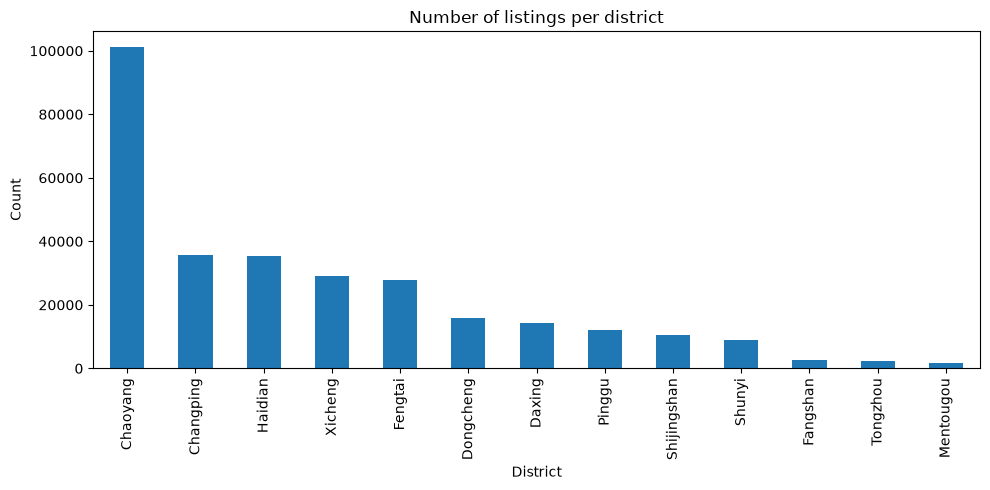

In [10]:
df["district_name"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of listings per district")
plt.xlabel("District")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [11]:
df["buildingType"].unique()

array([1, 4, 3, 2])

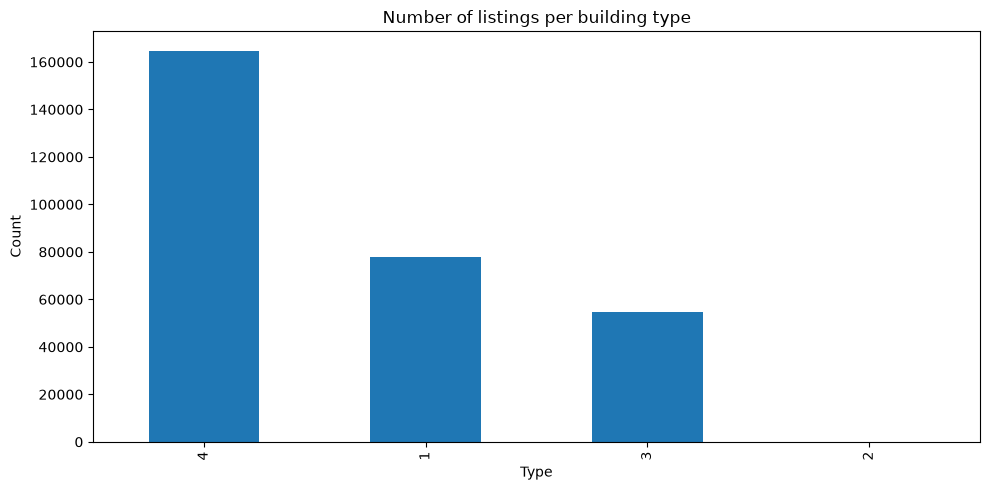

In [12]:
df["buildingType"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of listings per building type")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [13]:
df[["story_type", "story"]] = df["floor"].str.split(" ", n=1, expand=True)

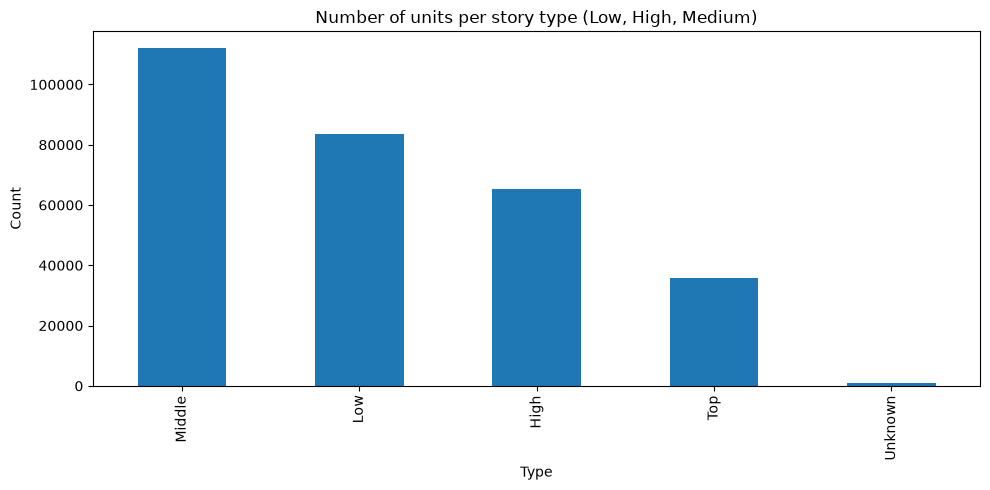

In [14]:
df["story_type"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of units per story type (Low, High, Medium)")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

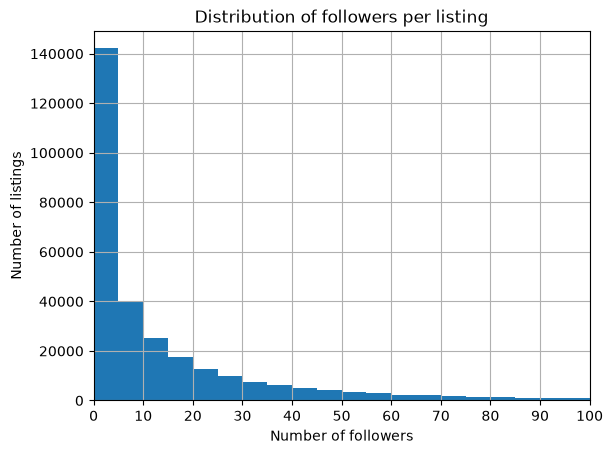

In [15]:
ax = df["followers"].hist(bins=range(0, 101, 5))
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))   # markers at 0, 10, 20, ... 100
ax.set_title("Distribution of followers per listing")
ax.set_xlabel("Number of followers")
ax.set_ylabel("Number of listings")
plt.show()

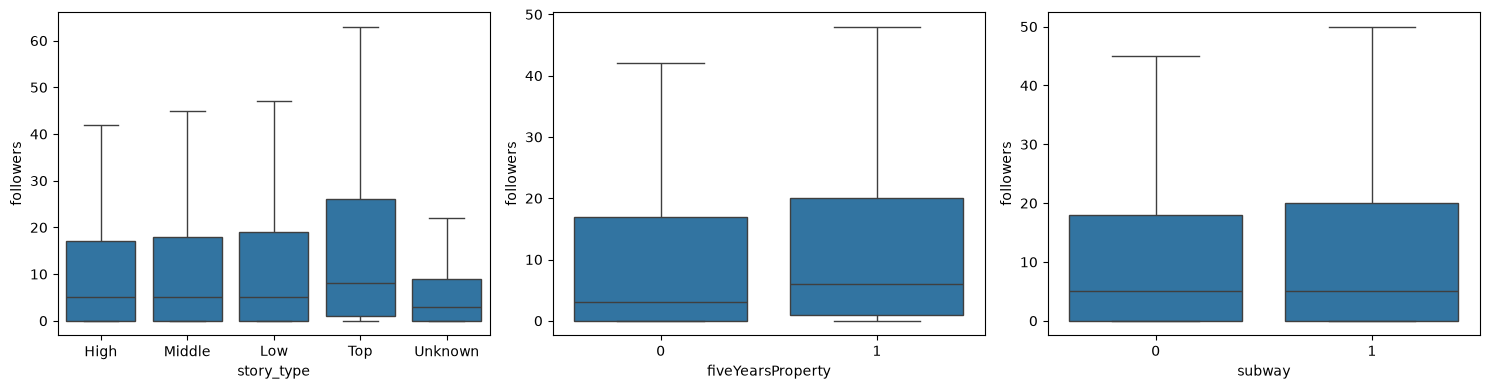

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["story_type", "fiveYearsProperty", "subway"]):
    sns.boxplot(data=df, x=col, y="followers", showfliers=False, ax=ax)
plt.tight_layout()
plt.show()

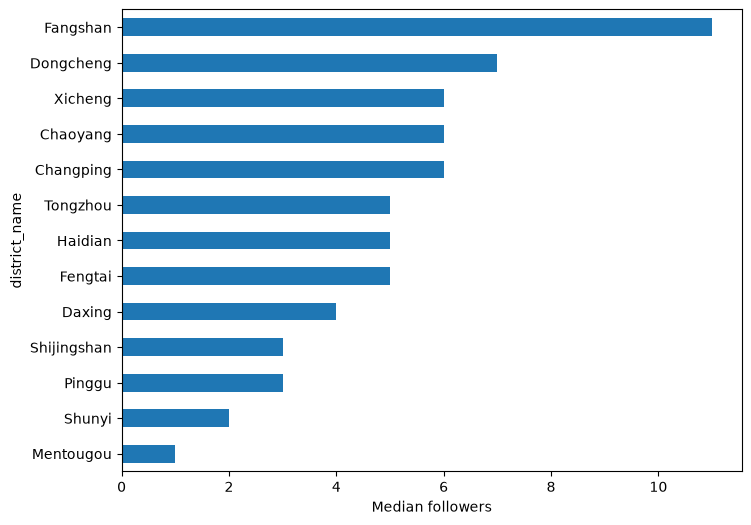

In [17]:
df.groupby("district_name")["followers"].median().sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Median followers")
plt.show()

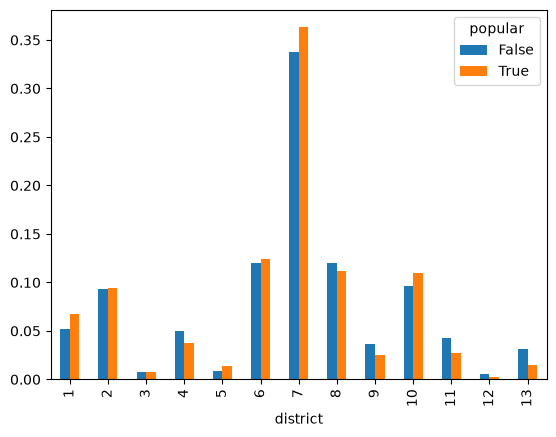

In [18]:
df["popular"] = df["followers"] >= df["followers"].quantile(0.9)   # has follower count in the top 10% most followed listings

pd.crosstab(df["district"], df["popular"], normalize="columns").plot(kind="bar")
plt.show()